## Negative Affect

> Do you feel worry, anger or sadness

# Imports

In [1]:
import matplotlib.pyplot as plt
from scipy import stats

from Q1.consts import *

from utils.read_csv_to_df import read_csv_to_df
from utils.plot_hist_with_normal_dist_overlay import plot_hist_with_normal_dist_overlay
from utils.rule_of_thumb__skewness import rule_of_thumb__skewness
from utils.rule_of_thumb__kurtosis import rule_of_thumb__kurtosis
from utils.plot_correlation_to_target import plot_correlation_to_target
from utils.preprocessing.transform import *

# Defaults

In [2]:
COLUMN = columns['NA']

# Fetch Data

In [3]:
train_df = read_csv_to_df(path=TRAIN_PATH)

# Summary

In [4]:
train_df[COLUMN].info()

NegativeAffect_stats = train_df[[COLUMN]].describe().T

q1, q3 = train_df[COLUMN].quantile(0.25), train_df[COLUMN].quantile(0.75)
iqr = q3 - q1
NegativeAffect_stats['IQR outliers'] = (
	(train_df[COLUMN] < q1 - 1.5 * iqr) | (train_df[COLUMN] > q3 + 1.5 * iqr)
).sum()

NegativeAffect_stats

<class 'pandas.core.series.Series'>
RangeIndex: 1559 entries, 0 to 1558
Series name: Negative affect
Non-Null Count  Dtype  
--------------  -----  
1545 non-null   float64
dtypes: float64(1)
memory usage: 12.3 KB


,count,mean,std,min,25%,50%,75%,max,IQR outliers
Negative affect,1545.0,0.267644,0.084431,0.083,0.206,0.258,0.319,0.705,20


In [5]:
missing_values_NegativeAffect = train_df[COLUMN].isna().sum()
count_NegativeAffect = train_df[COLUMN].count()

print(f"{missing_values_NegativeAffect} missing values out of {count_NegativeAffect} -> {round(missing_values_NegativeAffect / count_NegativeAffect, 2)}%")

14 missing values out of 1545 -> 0.01%


# Plots

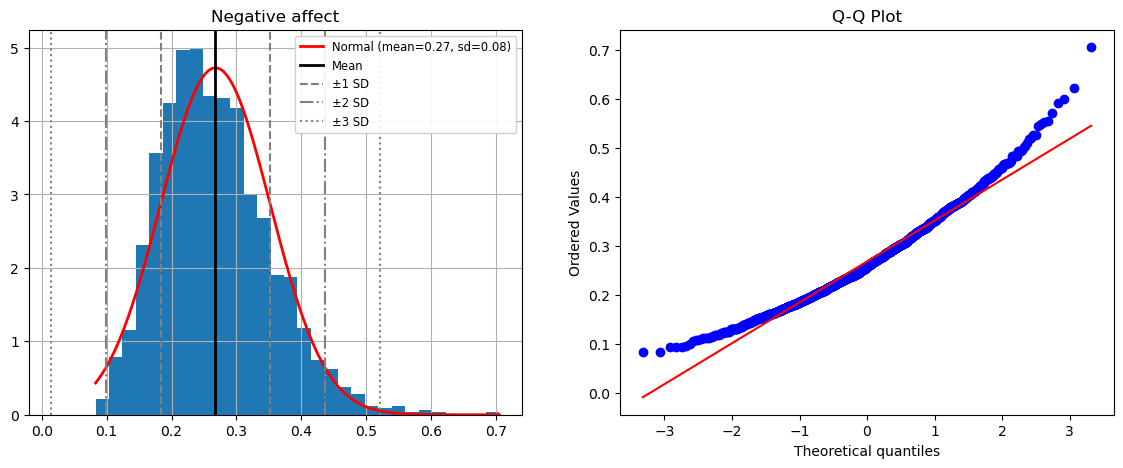

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

plot_hist_with_normal_dist_overlay(
    series=train_df[COLUMN],
    bins=HIST_BINS,
    ax=ax1
)

stats.probplot(
	train_df[COLUMN].dropna(),
	dist="norm",
	plot=ax2)
ax2.set_title("Q-Q Plot")

plt.show()

# Correlation to Target

<Axes: title={'center': 'Life Ladder vs Negative affect'}, xlabel='Negative affect', ylabel='Life Ladder'>

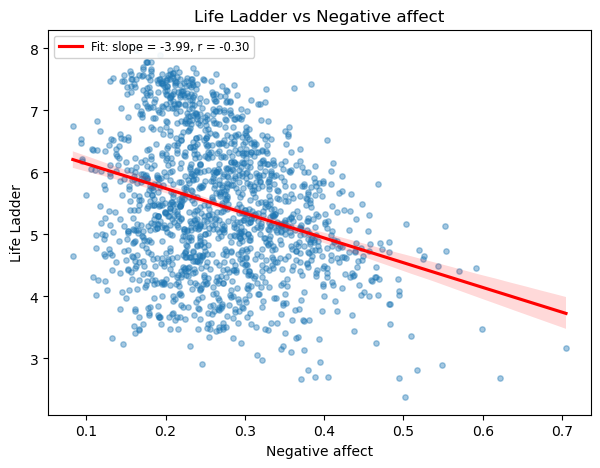

In [7]:
plot_correlation_to_target(
	df=train_df,
	feature="Negative affect",
	target=TARGET,
)

In [8]:
correlation_to_target_NegativeAffect = train_df[TARGET].corr(train_df["Negative affect"])
print(f"Correlation: {correlation_to_target_NegativeAffect:.3f}")

Correlation: -0.302


# Skew & Kurtosis

In [9]:
NegativeAffectSkew = train_df[COLUMN].skew()
NegativeAffectSkew_RuleOfThumb = rule_of_thumb__skewness(series=train_df["Negative affect"])
NegativeAffectKurtosis = train_df[COLUMN].kurt()
NegativeAffectKurtosis_RuleOfThumb = rule_of_thumb__kurtosis(series=train_df[COLUMN])

print(f'Negative Affect Skew: {NegativeAffectSkew:.3f} -> {NegativeAffectSkew_RuleOfThumb}')
print(f'Negative Affect Kurtosis: {NegativeAffectKurtosis:.3f} -> {NegativeAffectKurtosis_RuleOfThumb}')

Negative Affect Skew: 0.696 -> Moderately skewed
Negative Affect Kurtosis: 0.801 -> Mesokurtic (near-normal tails)


In [10]:
NegativeAffectSkewTransformed = compare_all_transforms(series=train_df["Negative affect"])
NegativeAffectSkewTransformed

,skew_before,skew_after,skew_diff,kurt_before,kurt_after,kurt_diff,skew_rule_after
transform,,,,,,,
box_cox,0.696474,-0.001932,-6.984065e-01,0.801214,-0.064307,-8.655209e-01,Roughly symmetric
rank,0.696474,-0.005763,-7.022376e-01,0.801214,-1.198509,-1.999722e+00,Roughly symmetric
yeo_johnson,0.696474,0.014468,-6.820068e-01,0.801214,-0.257279,-1.058493e+00,Roughly symmetric
quantile,0.696474,-0.062044,-7.585187e-01,0.801214,0.928739,1.275256e-01,Roughly symmetric
logit,0.696474,0.132662,-5.638127e-01,0.801214,0.223766,-5.774473e-01,Roughly symmetric
sqrt,0.696474,0.228431,-4.680437e-01,0.801214,0.023415,-7.777990e-01,Roughly symmetric
log,0.696474,-0.235408,-9.318822e-01,0.801214,0.038860,-7.623535e-01,Roughly symmetric
arcsine_sqrt,0.696474,0.427122,-2.693522e-01,0.801214,0.396858,-4.043558e-01,Roughly symmetric
log1p,0.696474,0.486037,-2.104370e-01,0.801214,0.283110,-5.181042e-01,Roughly symmetric


---

### Notes / Observations
#### General
- 14 missing values (0.9% of rows).
- A 0 to 1 share ranging from 0.08 to 0.71 (mean 0.27, median 0.26).
- Right skewed (skew 0.70, kurtosis 0.80): a peak around 0.23 and a thin tail of high worry countries, with 20 high IQR outliers (above about 0.49).
- Weak negative link to happiness (r = -0.30). The scatter is a wide cloud; the line slopes down, but much of the trend comes from the few high values.
- Most related to Social support (r = -0.40): countries with less support report more worry, anger and sadness.
- **Takeaway:** weak predictor; may add a little on top of the stronger features.

#### Transforming
- Worth transforming: moderately right skewed.
- Unlike the left skewed features, log and sqrt help here because the tail is on the high side: log gives -0.24 and sqrt 0.23. All values are above 0, so log is allowed.
- yeo_johnson works best: skew 0.70 to 0.01, kurtosis 0.80 to -0.26.
- square and cube make it much worse (1.82, 3.52) by stretching the high tail.
- **Pick:** yeo_johnson, or log as a simpler option that is easier to explain.

#### Scaling
- StandardScaler after the transform.
- Avoid MinMaxScaler on the raw values: the high outliers set the maximum, squeezing most countries into the bottom of the range.

#### Imputing
- 12 of the 14 missing rows are also missing Positive affect, so Positive affect cannot help fill these.
- Social support (r = -0.40) is the best remaining source, but the links are weak, so model based imputation gains little.
- Median SimpleImputer (0.258) is the practical choice, slightly below the mean (0.268) because of the right skew.